## Importation des bibliothèques nécessaires à l'analyse des données.

In [4]:
import requests
import feedparser
import time
from pathlib import Path
import pyarrow.parquet as pq
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Définition de l'URL de l'API arXiv et des en-têtes de requête.

In [5]:
API_URL = "https://export.arxiv.org/api/query"

HEADERS = {
    "User-Agent": "arxiv-category-counter/1.0"
}

## Sélection des catégories arXiv et des répertoires du projet.

In [6]:
CATEGORIES = [
    "cs.AI",
    "cs.LG",
    "cs.CV",
    "cs.CL",
    "cs.IR",
    "cs.NE",
    "cs.RO",
    "cs.DS",
    "cs.DB",
    "cs.CR",
    "math.NA",
    "math.OC",
    "math.PR",
    "math.ST",
    "math.IT",
    "math.CO",
]

PROJECT_ROOT = Path("/home/abdelkarim/project/arxiv-bot")
OUTPUT_DIR = PROJECT_ROOT / "data" / "metadata"

## Création d'une fonction qui récupère le nombre d'articles d'une catégorie.

In [7]:
def get_category_count(category):

    params = {
        "search_query" : f"cat:{category}",
        "start" : 0,
        "max_results" : 1
    }

    response = requests.get(
        API_URL,
        params = params,
        headers = HEADERS,
        timeout = 60
    )

    response.raise_for_status()

    feed = feedparser.parse(response.content)

    total = feed.feed.get("opensearch_totalresults")

    if total is None:
        raise ValueError(
            f"Impossible de récupérer le nombre pour {category}"
        )

    return int(total)

## Interrogation de l'API pour compter les articles de chaque catégorie.

In [8]:
results = {}

print("=" * 60)
print("COMPTAGE DES ARTICLES ARXIV")
print("=" * 60)

for category in CATEGORIES:

    print(f"\nRecherche : {category} ...")

    try:
        count = get_category_count(category)

        results[category] = count

        print(f"→ {count:,} articles")

    except Exception as e:
        print(f"Erreur : {e}")

    # Respect de l'API arXiv
    time.sleep(3)


COMPTAGE DES ARTICLES ARXIV

Recherche : cs.AI ...
→ 198,384 articles

Recherche : cs.LG ...
→ 284,271 articles

Recherche : cs.CV ...
→ 204,480 articles

Recherche : cs.CL ...
→ 118,311 articles

Recherche : cs.IR ...
→ 27,005 articles

Recherche : cs.NE ...
→ 18,224 articles

Recherche : cs.RO ...
→ 57,578 articles

Recherche : cs.DS ...
→ 29,838 articles

Recherche : cs.DB ...
→ 12,328 articles

Recherche : cs.CR ...
→ 51,699 articles

Recherche : math.NA ...
→ 51,379 articles

Recherche : math.OC ...
→ 63,981 articles

Recherche : math.PR ...
→ 67,797 articles

Recherche : math.ST ...
→ 28,869 articles

Recherche : math.IT ...
→ 0 articles

Recherche : math.CO ...
→ 81,732 articles


## Affichage du total d'articles par catégorie et du total général.

In [9]:
print("\n")
print("=" * 60)
print("NOMBRE D'ARTICLES PAR CATÉGORIE")
print("=" * 60)

total = 0

for category, count in results.items():

    print(f"{category:<10} : {count:>12,}")

    total += count

print("=" * 60)
print(f"{'TOTAL':<10} : {total:>12,}")
print("=" * 60)



NOMBRE D'ARTICLES PAR CATÉGORIE
cs.AI      :      198,384
cs.LG      :      284,271
cs.CV      :      204,480
cs.CL      :      118,311
cs.IR      :       27,005
cs.NE      :       18,224
cs.RO      :       57,578
cs.DS      :       29,838
cs.DB      :       12,328
cs.CR      :       51,699
math.NA    :       51,379
math.OC    :       63,981
math.PR    :       67,797
math.ST    :       28,869
math.IT    :            0
math.CO    :       81,732
TOTAL      :    1,295,876


## Comptage des identifiants d'articles déjà stockés dans les fichiers Parquet.

In [10]:
ids = set()
for f in OUTPUT_DIR.glob("batch_*.parquet"):
    import pyarrow.parquet as pq
    table = pq.read_table(f, columns=["arxiv_id"])
    ids.update(table["arxiv_id"].to_pylist())

print(f"NOMBRE D'ARTICLES STOCKER : {len(ids)}")

NOMBRE D'ARTICLES STOCKER : 35233


## Chargement et concaténation des fichiers Parquet dans un DataFrame.

In [11]:
parquet_files = sorted(OUTPUT_DIR.glob("*.parquet"))

df = pd.concat(
    [pd.read_parquet(file) for file in parquet_files],
    ignore_index=True
)

## Aperçu des premières lignes du DataFrame.

In [12]:
df.head()

,arxiv_id,title,authors,abstract,published,url,pdf_url,page_count,pages,source
0,2608.27424,Beyond F1: Evaluating Coverage and Failure Rec...,"[Qianlong Lan, Vinothini Pandurangan, Anuj Kau...",Static scanners are increasingly used to ident...,2026-08-27T17:49:28Z,http://arxiv.org/abs/2608.27424v1,https://arxiv.org/pdf/2608.27424.pdf,10,"[{'page': 1, 'text': 'BEYOND F1: EVALUATING CO...",arxiv
1,2608.27427,Persona-Execution Separation: An Architecture ...,[Yisen Xi],Large language model (LLM) agents in governed ...,2026-08-27T17:50:07Z,http://arxiv.org/abs/2608.27427v1,https://arxiv.org/pdf/2608.27427.pdf,36,"[{'page': 1, 'text': 'Persona–Execution Separa...",arxiv
2,2608.27454,WikiSkill: Compiling Agent Experience into Per...,"[Liyan Tang, Cyrus Rashtchian, Chun-Sung Ferng...",Agent skills package specialized knowledge and...,2026-08-27T17:59:11Z,http://arxiv.org/abs/2608.27454v1,https://arxiv.org/pdf/2608.27454.pdf,28,"[{'page': 1, 'text': '2026-08-28 WikiSkill: C...",arxiv
3,2608.27421,Learning a Continuous Sepsis Severity Score Wi...,"[Kevin Zhu, Ryan Zhang, Baraa Abed, Tilendra C...",Currently used sepsis severity indices rely on...,2026-08-27T17:46:21Z,http://arxiv.org/abs/2608.27421v1,https://arxiv.org/pdf/2608.27421.pdf,18,"[{'page': 1, 'text': 'Learning a Continuous Se...",arxiv
4,2608.27402,How Language Models Organize and Structure Mor...,[Orion Reblitz-Richardson],How do large language models (LLMs) organize m...,2026-08-27T17:30:30Z,http://arxiv.org/abs/2608.27402v1,https://arxiv.org/pdf/2608.27402.pdf,32,"[{'page': 1, 'text': 'How Language Models Orga...",arxiv


## Vérification du nombre de lignes et de colonnes du DataFrame.

In [13]:
df.shape

(35233, 10)

## Inspection des types de données et de la structure du DataFrame.

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35233 entries, 0 to 35232
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   arxiv_id    35233 non-null  str   
 1   title       35233 non-null  str   
 2   authors     35233 non-null  object
 3   abstract    35233 non-null  str   
 4   published   35233 non-null  str   
 5   url         35233 non-null  str   
 6   pdf_url     35233 non-null  str   
 7   page_count  35233 non-null  int64 
 8   pages       35233 non-null  object
 9   source      35233 non-null  str   
dtypes: int64(1), object(2), str(7)
memory usage: 52.4+ MB


## Affichage de la liste des colonnes disponibles.

In [15]:
df.columns.tolist()

['arxiv_id',
 'title',
 'authors',
 'abstract',
 'published',
 'url',
 'pdf_url',
 'page_count',
 'pages',
 'source']

## Détection du nombre de valeurs manquantes par colonne.

In [16]:
df.isna().sum()

arxiv_id      0
title         0
authors       0
abstract      0
published     0
url           0
pdf_url       0
page_count    0
pages         0
source        0
dtype: int64

## Détection du nombre de valeurs manquantes par colonne.

In [17]:
df["url"].nunique()

35233

## Vérification du nombre d'URL distinctes dans les données.

In [18]:
df["title_length"] = df["title"].str.len()
df["title_length"].describe()

count    35233.000000
mean        80.883007
std         25.027285
min          8.000000
25%         64.000000
50%         80.000000
75%         96.000000
max        240.000000
Name: title_length, dtype: float64

## Calcul de la longueur des titres et de ses statistiques descriptives.

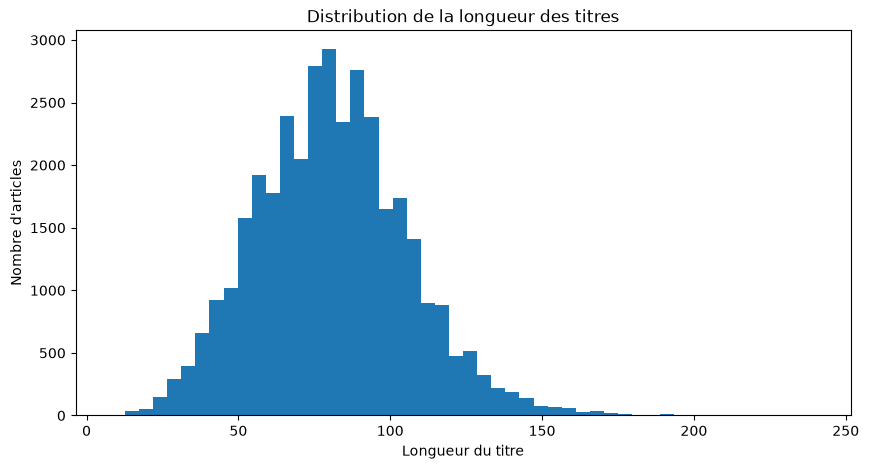

In [19]:
plt.figure(figsize=(10, 5))
plt.hist(df["title_length"], bins=50)
plt.xlabel("Longueur du titre")
plt.ylabel("Nombre d'articles")
plt.title("Distribution de la longueur des titres")
plt.show()

## Visualisation de la distribution de la longueur des titres.

In [20]:
df["abstract_length"] = df["abstract"].str.len()
df["abstract_length"].describe()

count    35233.000000
mean      1294.622030
std        389.193945
min         62.000000
25%       1034.000000
50%       1330.000000
75%       1590.000000
max       3199.000000
Name: abstract_length, dtype: float64

## Calcul de la longueur des résumés et de ses statistiques descriptives.

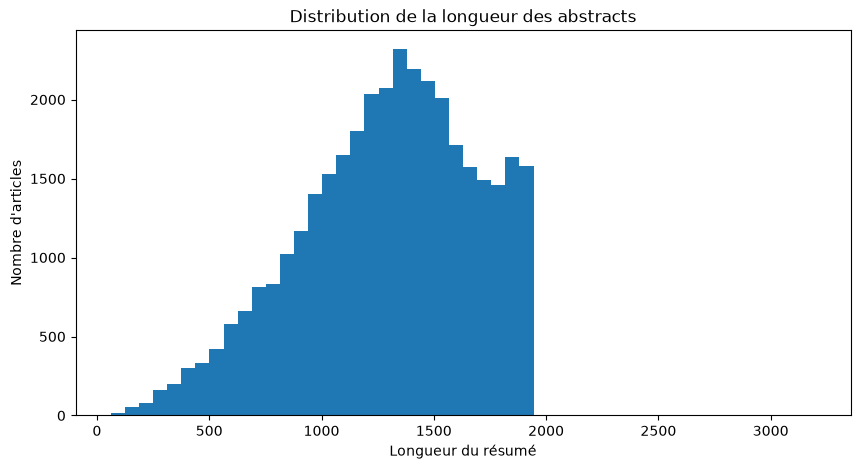

In [21]:
plt.figure(figsize=(10, 5))
plt.hist(df["abstract_length"], bins=50)
plt.xlabel("Longueur du résumé")
plt.ylabel("Nombre d'articles")
plt.title("Distribution de la longueur des abstracts")
plt.show()

## Visualisation de la distribution de la longueur des résumés.

In [22]:
df["page_count"].describe()

count    35233.000000
mean        23.904805
std         21.361879
min          1.000000
25%         12.000000
50%         19.000000
75%         30.000000
max        708.000000
Name: page_count, dtype: float64

## Analyse statistique du nombre de pages par article.

/tmp/ipykernel_72206/1912392400.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["page_count"].dropna(), vert=False)


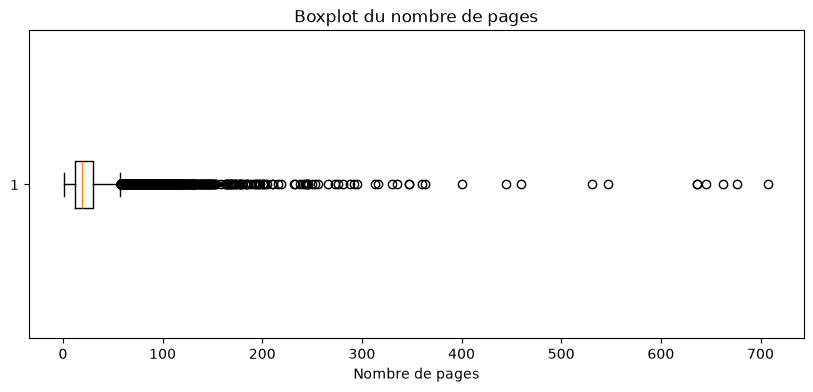

In [23]:
plt.figure(figsize=(10, 4))
plt.boxplot(df["page_count"].dropna(), vert=False)
plt.xlabel("Nombre de pages")
plt.title("Boxplot du nombre de pages")
plt.show()

## Visualisation de la dispersion du nombre de pages.

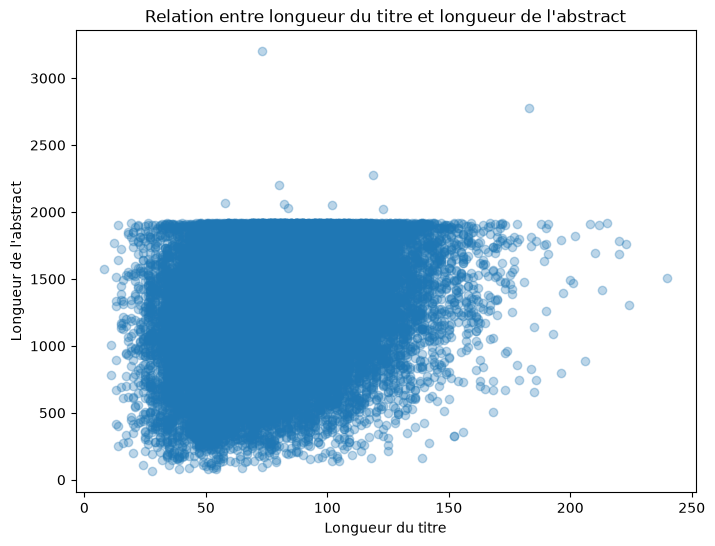

In [24]:
plt.figure(figsize=(8, 6))
plt.scatter(df["title_length"], df["abstract_length"], alpha=0.3)
plt.xlabel("Longueur du titre")
plt.ylabel("Longueur de l'abstract")
plt.title("Relation entre longueur du titre et longueur de l'abstract")
plt.show()

## Étude de la relation entre la longueur des titres et celle des résumés.

In [25]:
df["published"] = pd.to_datetime(df["published"])
df["year"] = df["published"].dt.year

df["year"].value_counts().sort_index()

year
2024      230
2025     4651
2026    30352
Name: count, dtype: int64

## Conversion des dates de publication et extraction de l'année.

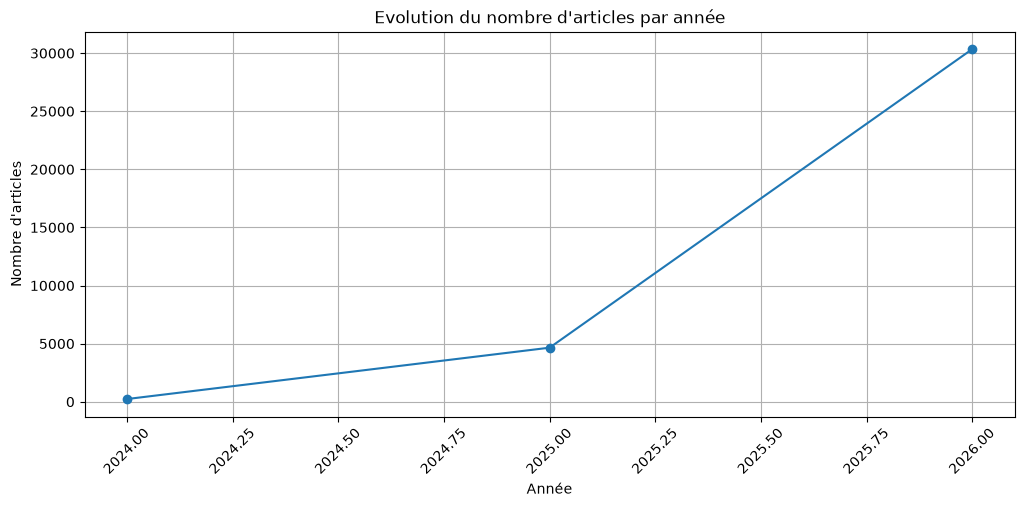

In [26]:
year_counts = df["year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(year_counts.index, year_counts.values, marker="o")
plt.xlabel("Année")
plt.ylabel("Nombre d'articles")
plt.title("Evolution du nombre d'articles par année")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

## Visualisation de l'évolution annuelle du nombre d'articles.

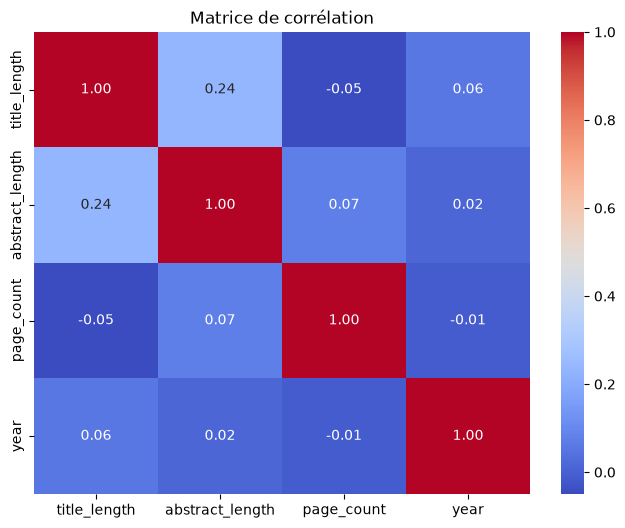

In [27]:
numeric_cols = [
    "title_length",
    "abstract_length",
    "page_count",
    "year"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice de corrélation")
plt.show()

## Calcul et visualisation de la matrice de corrélation des variables numériques.

In [28]:
df["arxiv_id"].duplicated().sum()

np.int64(0)

## Vérification des identifiants arXiv dupliqués.

In [29]:
df["url"].duplicated().sum()

np.int64(0)

## Vérification des URL dupliquées.

In [30]:
df["title"].duplicated().sum()

np.int64(0)

## Vérification des titres dupliqués.

In [31]:
100 * df.isna().mean()

arxiv_id           0.0
title              0.0
authors            0.0
abstract           0.0
published          0.0
url                0.0
pdf_url            0.0
page_count         0.0
pages              0.0
source             0.0
title_length       0.0
abstract_length    0.0
year               0.0
dtype: float64

## Calcul du pourcentage de valeurs manquantes par colonne.

In [32]:
columns = ["title_length", "abstract_length", "page_count"]

for column in columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df[
        (df[column] < lower) |
        (df[column] > upper)
    ]

    print("=" * 80)
    print(f"Colonne : {column}")
    print(f"Q1        : {q1:.2f}")
    print(f"Q3        : {q3:.2f}")
    print(f"IQR       : {iqr:.2f}")
    print(f"Lower     : {lower:.2f}")
    print(f"Upper     : {upper:.2f}")
    print(f"Outliers  : {len(outliers)}")
    print("=" * 80)

    print()

Colonne : title_length
Q1        : 64.00
Q3        : 96.00
IQR       : 32.00
Lower     : 16.00
Upper     : 144.00
Outliers  : 440

Colonne : abstract_length
Q1        : 1034.00
Q3        : 1590.00
IQR       : 556.00
Lower     : 200.00
Upper     : 2424.00
Outliers  : 86

Colonne : page_count
Q1        : 12.00
Q3        : 30.00
IQR       : 18.00
Lower     : -15.00
Upper     : 57.00
Outliers  : 1533

